# Stage A: control panel
The notebook only **launches** and **watches** the training. The training itself runs as a separate background process,
so closing/interrupting this notebook (or the Jupyter server) does NOT stop it. Results are saved as files in `stageA/`.

In [1]:
import os, sys, subprocess, glob, json, time
import numpy as np, pandas as pd
ROOT = r"C:\seeg_v2"
OUT  = r"C:\seeg_v2\features_hifigan"
os.chdir(ROOT); os.environ["SEEG_OUT_DIR"] = OUT
PY = sys.executable
print("python:", PY)
print("subjects found:", len(glob.glob(os.path.join(OUT, "sub-*_feat.npy"))))

python: C:\seeg_v2\.venv\Scripts\python.exe
subjects found: 10


## 1) Smoke test (about 2 minutes, runs here)

In [2]:
r = subprocess.run([PY, "stageA_pooled.py", "smoke", "run", "baseline"], capture_output=True, text=True)
print(r.stdout[-3000:]); print(r.stderr[-2000:])

baseline: 2 participants | train windows 444, val 40, test 40
    [baseline lr=0.0003 seed=42] epoch 1/1: train MSE 0.6614 | val MSE 0.4645 | 9s
  baseline: lr 0.0003 -> best validation MSE 0.4645
  baseline: chosen lr = 0.0003
  baseline_lr0.0003_seed42: already done, skipped
model      runs                  pcc         template_pcc         residual_pcc        pcc_in_speech   template_in_speech
baseline      1       0.739 +- 0.000       0.759 +- 0.000       0.412 +- 0.000       0.190 +- 0.000       0.204 +- 0.000




## 2) Launch the real run in the background (linear, baseline, hybrid, one after another)

In [3]:
MODELS = ["linear", "baseline", "hybrid", "baseline_null", "hybrid_null"]   # NeuroIncept / ConvED-SR are added later
bat = os.path.join(ROOT, "run_stageA.bat")
with open(bat, "w") as f:
    f.write("@echo off\r\ncd /d " + ROOT + "\r\nset SEEG_OUT_DIR=" + OUT + "\r\n")
    for m in MODELS:
        f.write(f'"{PY}" stageA_pooled.py run {m} >> stageA_run.log 2>&1\r\n')
DETACHED, NEWGROUP = 0x00000008, 0x00000200
p = subprocess.Popen(["cmd", "/c", bat], creationflags=DETACHED | NEWGROUP, close_fds=True)
print("launched, pid", p.pid, "-> do NOT launch it twice")

launched, pid 14428 -> do NOT launch it twice


## 3) Watch (run this cell as often as you like)

In [ ]:
log = os.path.join(ROOT, "stageA_run.log")
print("".join(open(log, errors="replace").readlines()[-25:]) if os.path.exists(log) else "no log yet")

In [ ]:
print(subprocess.run([PY, "stageA_pooled.py", "summary"], capture_output=True, text=True).stdout)

## 4) Per-participant results

In [4]:
rows = []
for pth in sorted(glob.glob(os.path.join(OUT, "stageA", "*.json"))):
    j = json.load(open(pth)); tag = os.path.basename(pth)[:-5]
    for sub, r in j["per_subject"].items():
        rows.append(dict(run=tag, subject=sub, **{k: round(v, 3) for k, v in r.items() if k in
                    ("pcc", "template_pcc", "residual_pcc", "pcc_in_speech", "template_in_speech")}))
df = pd.DataFrame(rows)
df.to_csv(os.path.join(ROOT, "stageA_per_subject.csv"), index=False)
df

,run,subject,pcc,template_pcc,residual_pcc,pcc_in_speech,template_in_speech
0,baseline_lr0.0001_seed123,sub-01,0.579,0.664,0.351,0.199,0.190
1,baseline_lr0.0001_seed123,sub-02,0.617,0.733,0.324,0.071,0.155
2,baseline_lr0.0001_seed123,sub-03,0.731,0.816,0.288,0.239,0.282
3,baseline_lr0.0001_seed123,sub-04,0.737,0.805,0.333,0.223,0.306
4,baseline_lr0.0001_seed123,sub-05,0.598,0.741,0.284,0.175,0.247
...,...,...,...,...,...,...,...
85,linear_seedNA,sub-06,0.708,0.784,0.248,0.230,0.252
86,linear_seedNA,sub-07,0.429,0.684,0.085,0.171,0.288
87,linear_seedNA,sub-08,0.581,0.815,0.147,0.157,0.253
88,linear_seedNA,sub-09,0.412,0.792,0.003,0.226,0.235


In [5]:
import os, subprocess, sys
ROOT = r"C:\seeg_v2"
os.chdir(ROOT)

# تأكدي أن الملفات موجودة
for f in ["part2_watcher.py", "stageA_extra.py", "stageA_pooled.py"]:
    print(f, os.path.exists(os.path.join(ROOT, f)))

# منع التشغيل المزدوج
if os.path.exists(os.path.join(ROOT, "stageA_run2.log")):
    print("يوجد stageA_run2.log: على الأغلب شُغّل من قبل. لا تشغّلي مرة ثانية قبل أن ترسلي لي آخر أسطره.")
else:
    bat = os.path.join(ROOT, "run_part2.bat")
    open(bat, "w").write(
        f'@echo off\ncd /d {ROOT}\nset SEEG_OUT_DIR={ROOT}\\features_hifigan\n'
        f'"{sys.executable}" part2_watcher.py\n')
    DETACHED, NEWGROUP = 0x00000008, 0x00000200
    subprocess.Popen(["cmd", "/c", bat], creationflags=DETACHED | NEWGROUP, close_fds=True)
    print("بدأ الجزء الثاني في الخلفية.")

part2_watcher.py True
stageA_extra.py True
stageA_pooled.py True
بدأ الجزء الثاني في الخلفية.


In [7]:
print(open(r"C:\seeg_v2\stageA_run2.log", encoding="utf-8").read()[-1500:])

   [neuroincept lr=0.0001 seed=42] epoch 9/60: train loss 0.3759 | val MSE 0.6690 | 105s
    [neuroincept lr=0.0001 seed=42] epoch 10/60: train loss 0.3479 | val MSE 0.6556 | 116s
    [neuroincept lr=0.0001 seed=42] epoch 11/60: train loss 0.3335 | val MSE 0.6476 | 114s
    [neuroincept lr=0.0001 seed=42] epoch 12/60: train loss 0.3213 | val MSE 0.6559 | 116s
    [neuroincept lr=0.0001 seed=42] epoch 13/60: train loss 0.3135 | val MSE 0.6606 | 118s
    [neuroincept lr=0.0001 seed=42] epoch 14/60: train loss 0.3055 | val MSE 0.6586 | 119s
  neuroincept: lr 0.0001 -> best validation MSE 0.6471
    [neuroincept lr=0.0003 seed=42] epoch 1/60: train loss 0.8387 | val MSE 0.6990 | 107s
    [neuroincept lr=0.0003 seed=42] epoch 2/60: train loss 0.6073 | val MSE 0.6703 | 109s
    [neuroincept lr=0.0003 seed=42] epoch 3/60: train loss 0.5443 | val MSE 0.6490 | 111s
    [neuroincept lr=0.0003 seed=42] epoch 4/60: train loss 0.4652 | val MSE 0.6472 | 112s
    [neuroincept lr=0.0003 seed=42] epoch

In [4]:
import glob, os
d = r"C:\seeg_v2"
print("".join(open(os.path.join(d, "stageA_run2.log"), encoding="utf-8", errors="replace").readlines()[-8:]))
print()
for m in ["neuroincept", "convedsr", "neuroincept_null", "convedsr_null"]:
    f = glob.glob(os.path.join(d, "features_hifigan", "stageA", f"{m}_lr*_seed*.json"))
    print(m, len(f), "finished run(s)")

2026-10-11 04:19:23 neuroincept_null: smoke test OK, starting the full run
neuroincept_null: 10 participants | params 4,672,144
    [neuroincept_null lr=0.001 seed=42] epoch 1/60: train loss 0.9957 | val MSE 1.0275 | 111s
    [neuroincept_null lr=0.001 seed=42] epoch 2/60: train loss 0.9956 | val MSE 1.0306 | 245s
    [neuroincept_null lr=0.001 seed=42] epoch 3/60: train loss 0.9886 | val MSE 1.0293 | 1704s
    [neuroincept_null lr=0.001 seed=42] epoch 4/60: train loss 0.9947 | val MSE 1.0290 | 1470s
    [neuroincept_null lr=0.001 seed=42] epoch 5/60: train loss 0.9844 | val MSE 1.0285 | 1232s
    [neuroincept_null lr=0.001 seed=42] epoch 6/60: train loss 0.9828 | val MSE 1.0284 | 2256s


neuroincept 3 finished run(s)
convedsr 3 finished run(s)
neuroincept_null 0 finished run(s)
convedsr_null 0 finished run(s)


In [5]:
import os, sys, re, glob, importlib
ROOT = r"C:\seeg_v2"; os.chdir(ROOT); sys.path.insert(0, ROOT)
os.environ["SEEG_OUT_DIR"] = os.path.join(ROOT, "features_hifigan")
import pandas as pd, stageA_report as R; importlib.reload(R)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

# اختيار الـ lr ونتيجة كل run، لكل نموذج
for lg in sorted(glob.glob(os.path.join(os.environ["SEEG_OUT_DIR"], "stageA", "log_*.txt"))):
    print("\n==", os.path.basename(lg))
    for line in open(lg, errors="replace"):
        if re.search(r"best validation MSE|chosen lr|mean test PCC|already done", line):
            print(line.rstrip())

df = R.load_runs()
display(R.model_table(df))
display(R.subject_table(df, "pcc"))
display(R.subject_table(df, "pcc_in_speech"))


== log_baseline.txt
  baseline: lr 0.0001 -> best validation MSE 0.5677
  baseline: lr 0.0003 -> best validation MSE 0.5826
  baseline: lr 0.001 -> best validation MSE 0.5956
  baseline: chosen lr = 0.0001
  baseline_lr0.0001_seed42: mean test PCC 0.711 | template 0.744 | residual +0.370
  baseline_lr0.0001_seed123: mean test PCC 0.703 | template 0.744 | residual +0.373
  baseline_lr0.0001_seed456: mean test PCC 0.703 | template 0.744 | residual +0.369

== log_baseline_null.txt
  baseline_null: lr 0.0001 -> best validation MSE 1.0246
  baseline_null: chosen lr = 0.0001
  baseline_null_lr0.0001_seed42: mean test PCC 0.044 | template 0.744 | residual -0.007

== log_convedsr.txt
  convedsr: lr 0.0001 -> best validation MSE 0.9235
  convedsr: lr 0.0003 -> best validation MSE 0.7446
  convedsr: lr 0.001 -> best validation MSE 0.6969
  convedsr: chosen lr = 0.001
  convedsr_lr0.001_seed42: mean test PCC 0.586 | template 0.744 | residual +0.213
  convedsr_lr0.001_seed123: mean test PCC 0.592

,seeds,lr,PCC,template PCC,PCC − template,PCC in speech,template in speech,in speech − template,residual PCC
model,,,,,,,,,
"Linear (Verwoert-style, pooled)",1,NaN,+0.472,+0.744,-0.272,+0.161,+0.236,-0.075,+0.132
Baseline CNN-BiLSTM,3,0.0001,+0.705 ± 0.004,+0.744 ± 0.000,-0.039 ± 0.004,+0.219 ± 0.010,+0.236 ± 0.000,-0.017 ± 0.010,+0.371 ± 0.001
Hybrid (MR-ResBlocks),3,0.0001,+0.696 ± 0.004,+0.744 ± 0.000,-0.048 ± 0.004,+0.232 ± 0.006,+0.236 ± 0.000,-0.004 ± 0.006,+0.369 ± 0.006
NeuroIncept (re-impl.),3,0.0010,+0.427 ± 0.302,+0.744 ± 0.000,-0.318 ± 0.302,+0.126 ± 0.089,+0.236 ± 0.000,-0.110 ± 0.089,+0.208 ± 0.152
ConvED-SR-style (re-impl.),3,0.0010,+0.590 ± 0.003,+0.744 ± 0.000,-0.154 ± 0.003,+0.167 ± 0.005,+0.236 ± 0.000,-0.069 ± 0.005,+0.240 ± 0.019
"Baseline, noise input",1,0.0001,+0.044,+0.744,-0.701,+0.005,+0.236,-0.231,-0.007
"Hybrid, noise input",1,0.0001,+0.170,+0.744,-0.575,+0.041,+0.236,-0.195,-0.009


,"Linear (Verwoert-style, pooled)",Baseline CNN-BiLSTM,Hybrid (MR-ResBlocks),NeuroIncept (re-impl.),ConvED-SR-style (re-impl.),"Baseline, noise input","Hybrid, noise input",Template (no neural input)
subject,,,,,,,,
sub-01,0.059,0.569,0.558,0.292,0.390,0.088,0.174,0.664
sub-02,0.495,0.652,0.600,0.336,0.514,-0.024,0.201,0.733
sub-03,0.599,0.741,0.774,0.492,0.607,0.071,0.204,0.816
sub-04,0.493,0.747,0.718,0.450,0.649,0.076,0.241,0.805
sub-05,0.406,0.614,0.589,0.352,0.499,0.067,0.173,0.741
sub-06,0.708,0.842,0.847,0.548,0.789,0.078,0.212,0.784
sub-07,0.429,0.723,0.705,0.450,0.587,-0.026,0.258,0.684
sub-08,0.581,0.710,0.735,0.467,0.610,0.092,0.171,0.815
sub-09,0.412,0.795,0.777,0.477,0.671,0.048,0.149,0.792


,"Linear (Verwoert-style, pooled)",Baseline CNN-BiLSTM,Hybrid (MR-ResBlocks),NeuroIncept (re-impl.),ConvED-SR-style (re-impl.),"Baseline, noise input","Hybrid, noise input",Template (no neural input)
subject,,,,,,,,
sub-01,-0.007,0.164,0.194,0.064,0.107,0.035,0.036,0.190
sub-02,0.080,0.102,0.094,0.043,0.020,-0.001,0.084,0.155
sub-03,0.196,0.246,0.296,0.187,0.197,0.013,0.006,0.282
sub-04,0.140,0.216,0.189,0.131,0.217,0.017,0.063,0.306
sub-05,0.145,0.235,0.165,0.117,0.153,0.000,0.058,0.247
sub-06,0.230,0.388,0.418,0.242,0.353,-0.001,0.033,0.252
sub-07,0.171,0.287,0.282,0.145,0.194,-0.008,0.092,0.288
sub-08,0.157,0.142,0.211,0.124,0.130,0.015,-0.007,0.253
sub-09,0.226,0.213,0.217,0.067,0.091,-0.001,0.035,0.235


In [6]:
import os, time, glob, subprocess
d = r"C:\seeg_v2\features_hifigan\stageA"

# 1) آخر log تحدّث، ومنذ متى؟
logs = sorted(glob.glob(os.path.join(d, "log_*.txt")), key=os.path.getmtime)
last = logs[-1]
age = (time.time() - os.path.getmtime(last)) / 60
print("آخر ملف log:", os.path.basename(last), f"| آخر تحديث قبل {age:.1f} دقيقة")
print("".join(open(last, errors="replace").readlines()[-3:]))

# 2) هل عملية python تعمل وتستهلك CPU؟
out = subprocess.run(["tasklist", "/FI", "IMAGENAME eq python.exe"], capture_output=True, text=True).stdout
print(out)

آخر ملف log: log_neuroincept_null.txt | آخر تحديث قبل 36.6 دقيقة
    [neuroincept_null lr=0.001 seed=42] epoch 4/60: train loss 0.9947 | val MSE 1.0290 | 1470s
    [neuroincept_null lr=0.001 seed=42] epoch 5/60: train loss 0.9844 | val MSE 1.0285 | 1232s
    [neuroincept_null lr=0.001 seed=42] epoch 6/60: train loss 0.9828 | val MSE 1.0284 | 2256s


Image Name                     PID Session Name        Session#    Mem Usage
========================= ======== ================ =========== ============
python.exe                   11280 Console                    1      3,144 K
python.exe                    3024 Console                    1      8,252 K
python.exe                   10044 Console                    1      3,144 K
python.exe                    8904 Console                    1     32,976 K
python.exe                   12396 Console                    1     40,332 K
python.exe                   20340 Console                    1     40,932 K
python.exe                   290

In [7]:
print("".join(open(r"C:\seeg_v2\stageA_run2.log", encoding="utf-8", errors="replace").readlines()[-6:]))

    [neuroincept_null lr=0.001 seed=42] epoch 4/60: train loss 0.9947 | val MSE 1.0290 | 1470s
    [neuroincept_null lr=0.001 seed=42] epoch 5/60: train loss 0.9844 | val MSE 1.0285 | 1232s
    [neuroincept_null lr=0.001 seed=42] epoch 6/60: train loss 0.9828 | val MSE 1.0284 | 2256s
    [neuroincept_null lr=0.001 seed=42] epoch 7/60: train loss 0.9907 | val MSE 1.0278 | 2372s
    [neuroincept_null lr=0.001 seed=42] epoch 8/60: train loss 0.9934 | val MSE 1.0266 | 488s
    [neuroincept_null lr=0.001 seed=42] epoch 9/60: train loss 0.9839 | val MSE 1.0270 | 127s



In [8]:
import os, sys, subprocess
os.chdir(r"C:\seeg_v2"); os.environ["SEEG_OUT_DIR"] = r"C:\seeg_v2\features_hifigan"
r = subprocess.run([sys.executable, "stageA_stoi.py", "quick"], capture_output=True, text=True)
print(r.stdout[-3000:]); print(r.stderr[-1500:])

  sub-03|truth: STOI 0.740 | eSTOI 0.606 | 2 test blocks | 47s
  sub-03|template: STOI 0.421 | eSTOI -0.022 | 2 test blocks | 46s
  sub-03|hybrid: STOI 0.349 | eSTOI 0.000 | 2 test blocks | 47s
  sub-06|truth: STOI 0.748 | eSTOI 0.610 | 2 test blocks | 46s
  sub-06|template: STOI 0.448 | eSTOI 0.011 | 2 test blocks | 45s
  sub-06|hybrid: STOI 0.452 | eSTOI 0.091 | 2 test blocks | 46s
STOI per participant (mean over test blocks):
system   hybrid  template  truth
subject                         
sub-03    0.349     0.421  0.740
sub-06    0.452     0.448  0.748

mean over participants:
           stoi  estoi
system                
hybrid    0.400  0.046
template  0.434 -0.006
truth     0.744  0.608

C:\seeg_v2\.venv\Lib\site-packages\torch\nn\utils\weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)



In [9]:
from IPython.display import Audio, display
d = r"C:\seeg_v2\features_hifigan\stageA_audio"
for name in ["original", "truth", "template", "hybrid"]:
    print("sub-03", name); display(Audio(os.path.join(d, f"sub-03_{name}.wav")))

sub-03 original


sub-03 truth


sub-03 template


sub-03 hybrid


In [10]:
from IPython.display import Audio, display
import os
d = r"C:\seeg_v2\features_hifigan\stageA_audio"
for name in ["original", "truth", "template", "hybrid"]:
    print(name); display(Audio(os.path.join(d, f"sub-03_{name}.wav")))

original


truth


template


hybrid


In [11]:
import os, random
from IPython.display import Audio, display
d = r"C:\seeg_v2\features_hifigan\stageA_audio"
sub = "sub-06"                                   # جرّبي أيضاً sub-03
pair = ["hybrid", "template"]; random.shuffle(pair)
print("A"); display(Audio(os.path.join(d, f"{sub}_{pair[0]}.wav")))
print("B"); display(Audio(os.path.join(d, f"{sub}_{pair[1]}.wav")))
# بعد أن تقرّري أيهما أوضح، شغّلي هذا السطر لتعرفي الترتيب:
# print("A =", pair[0], "| B =", pair[1])

A


B


In [12]:
import os, sys, subprocess
os.chdir(r"C:\seeg_v2"); os.environ["SEEG_OUT_DIR"] = r"C:\seeg_v2\features_hifigan"
r = subprocess.run([sys.executable, "stageA_stoi.py", "sub-03", "sub-06"], capture_output=True, text=True)
print(r.stdout[-2500:])

  sub-03|linear: STOI 0.440 | eSTOI -0.005 | 2 test blocks | 42s
  sub-03|baseline: STOI 0.393 | eSTOI -0.032 | 2 test blocks | 41s
  sub-03|neuroincept: STOI 0.361 | eSTOI -0.019 | 2 test blocks | 40s
  sub-03|convedsr: STOI 0.253 | eSTOI -0.021 | 2 test blocks | 40s
  sub-06|linear: STOI 0.402 | eSTOI -0.013 | 2 test blocks | 42s
  sub-06|baseline: STOI 0.441 | eSTOI -0.016 | 2 test blocks | 39s
  sub-06|neuroincept: STOI 0.383 | eSTOI -0.028 | 2 test blocks | 43s
  sub-06|convedsr: STOI 0.309 | eSTOI -0.009 | 2 test blocks | 43s
STOI per participant (mean over test blocks):
system   baseline  convedsr  hybrid  linear  neuroincept  template  truth
subject                                                                  
sub-03      0.393     0.253   0.349   0.440        0.361     0.421  0.740
sub-06      0.441     0.309   0.452   0.402        0.383     0.448  0.748

mean over participants:
              stoi  estoi
system                   
baseline     0.417 -0.024
convedsr     0.28

In [13]:
from IPython.display import Audio, display
d = r"C:\seeg_v2\features_hifigan\stageA_audio"
for name in ["original", "baseline", "hybrid", "convedsr", "neuroincept", "linear", "template"]:
    print(name); display(Audio(os.path.join(d, f"sub-06_{name}.wav")))

original


baseline


hybrid


convedsr


neuroincept


linear


template


In [17]:
import os, time, glob, subprocess
ROOT = r"C:\seeg_v2"

def tail(path, n=5):
    if not os.path.exists(path):
        return "(الملف غير موجود)"
    age = (time.time() - os.path.getmtime(path)) / 60
    return f"[آخر تحديث قبل {age:.1f} دقيقة]\n" + "".join(open(path, encoding="utf-8", errors="replace").readlines()[-n:])

print("=== 1) الجزء الثاني من Stage A (stageA_run2.log)")
print(tail(os.path.join(ROOT, "stageA_run2.log"), 6))

print("\n=== 2) STOI الكامل (stoi_log.txt)")
print(tail(os.path.join(ROOT, "stoi_log.txt"), 6))

res = os.path.join(ROOT, "features_hifigan", "stageA_stoi", "stoi_results.json")
if os.path.exists(res):
    import json
    print("\nعدد نتائج STOI المنتهية:", len(json.load(open(res))), "من 70")

print("\n=== أحدث ملفات log في stageA")
d = os.path.join(ROOT, "features_hifigan", "stageA")
for f in sorted(glob.glob(os.path.join(d, "log_*.txt")), key=os.path.getmtime)[-3:]:
    print(os.path.basename(f), f"| قبل {(time.time()-os.path.getmtime(f))/60:.1f} دقيقة")

=== 1) الجزء الثاني من Stage A (stageA_run2.log)
[آخر تحديث قبل 494.3 دقيقة]
hybrid_null    1       0.170 +- 0.000       0.744 +- 0.000      -0.009 +- 0.000       0.041 +- 0.000       0.236 +- 0.000
linear        1       0.472 +- 0.000       0.744 +- 0.000       0.132 +- 0.000       0.161 +- 0.000       0.236 +- 0.000
neuroincept    3       0.427 +- 0.302       0.744 +- 0.000       0.208 +- 0.152       0.126 +- 0.089       0.236 +- 0.000
neuroincept_null    1      -0.000 +- 0.000       0.744 +- 0.000      -0.007 +- 0.000      -0.000 +- 0.000       0.236 +- 0.000
2026-10-11 08:55:01 convedsr_null: finished with exit code 0
2026-10-11 08:55:01 part 2 done


=== 2) STOI الكامل (stoi_log.txt)
[آخر تحديث قبل 497.5 دقيقة]


عدد نتائج STOI المنتهية: 70 من 70

=== أحدث ملفات log في stageA
log_convedsr.txt | قبل 770.5 دقيقة
log_neuroincept_null.txt | قبل 511.5 دقيقة
log_convedsr_null.txt | قبل 494.3 دقيقة


In [15]:
import os, sys, subprocess
ROOT = r"C:\seeg_v2"; os.chdir(ROOT)
bat = os.path.join(ROOT, "run_stoi.bat")
open(bat, "w").write(f'@echo off\ncd /d {ROOT}\nset SEEG_OUT_DIR={ROOT}\\features_hifigan\n"{sys.executable}" stageA_stoi.py > stoi_log.txt 2>&1\n')
subprocess.Popen(["cmd", "/c", bat], creationflags=0x00000008 | 0x00000200, close_fds=True)
print("STOI started; progress in C:\\seeg_v2\\stoi_log.txt")

STOI started; progress in C:\seeg_v2\stoi_log.txt


In [18]:
import os, sys, subprocess
ROOT = r"C:\seeg_v2"; os.chdir(ROOT)
print("script present:", os.path.exists(os.path.join(ROOT, "stageA_supp_neuroincept.py")))
if os.path.exists(os.path.join(ROOT, "run_supp.bat")):
    print("run_supp.bat موجود: على الأغلب جُدول من قبل. لا تشغّلي مرة ثانية.")
else:
    bat = os.path.join(ROOT, "run_supp.bat")
    open(bat, "w").write(f'@echo off\ncd /d {ROOT}\nset SEEG_OUT_DIR={ROOT}\\features_hifigan\n"{sys.executable}" stageA_supp_neuroincept.py\n')
    subprocess.Popen(["cmd", "/c", bat], creationflags=0x00000008 | 0x00000200, close_fds=True)
    print("scheduled: starts after 'part 2 done'")

script present: True
run_supp.bat موجود: على الأغلب جُدول من قبل. لا تشغّلي مرة ثانية.


In [19]:
import os, time, json, glob
ROOT = r"C:\seeg_v2"; F = os.path.join(ROOT, "features_hifigan")

def tail(path, n=4):
    if not os.path.exists(path): return "(الملف غير موجود)"
    age = (time.time() - os.path.getmtime(path)) / 60
    return f"[آخر تحديث قبل {age:.0f} دقيقة]\n" + "".join(open(path, encoding="utf-8", errors="replace").readlines()[-n:])

print("=== 1) الجزء الثاني من Stage A"); print(tail(os.path.join(ROOT, "stageA_run2.log"), 3))
print("\n=== 2) التشغيل الإضافي (NeuroIncept lr 1e-4)")
print(tail(os.path.join(F, "stageA_supp", "log_neuroincept_lr1e-4.txt"), 3))
print("منتهي:", len(glob.glob(os.path.join(F, "stageA_supp", "neuroincept_lr*_seed*.json"))), "من 3")
print("\n=== 3) STOI")
r = os.path.join(F, "stageA_stoi", "stoi_results.json")
print("عدد النتائج:", len(json.load(open(r))) if os.path.exists(r) else 0, "من 70")
print(tail(os.path.join(ROOT, "stoi_log.txt"), 3))

=== 1) الجزء الثاني من Stage A
[آخر تحديث قبل 497 دقيقة]
neuroincept_null    1      -0.000 +- 0.000       0.744 +- 0.000      -0.007 +- 0.000      -0.000 +- 0.000       0.236 +- 0.000
2026-10-11 08:55:01 convedsr_null: finished with exit code 0
2026-10-11 08:55:01 part 2 done


=== 2) التشغيل الإضافي (NeuroIncept lr 1e-4)
[آخر تحديث قبل 392 دقيقة]
    [neuroincept lr=0.0001 seed=456] epoch 14/60: train loss 0.3099 | val MSE 0.6715 | 119s
    [neuroincept lr=0.0001 seed=456] epoch 15/60: train loss 0.3033 | val MSE 0.6799 | 119s
  neuroincept_lr0.0001_seed456: mean test PCC 0.612 | template 0.744 | residual +0.271

منتهي: 3 من 3

=== 3) STOI
عدد النتائج: 70 من 70
[آخر تحديث قبل 500 دقيقة]



In [20]:
import subprocess, sys
os.environ["SEEG_OUT_DIR"] = F; os.chdir(ROOT)
print(subprocess.run([sys.executable, "stageA_stoi.py", "summary"], capture_output=True, text=True).stdout)

STOI per participant (mean over test blocks):
system   baseline  convedsr  hybrid  linear  neuroincept  template  truth
subject                                                                  
sub-01      0.286     0.201   0.291   0.194        0.178     0.291  0.676
sub-02      0.330     0.307   0.296   0.339        0.213     0.308  0.696
sub-03      0.393     0.253   0.349   0.440        0.361     0.421  0.740
sub-04      0.415     0.385   0.284   0.433        0.321     0.303  0.749
sub-05      0.382     0.315   0.301   0.361        0.228     0.371  0.732
sub-06      0.441     0.309   0.452   0.402        0.383     0.448  0.748
sub-07      0.286     0.253   0.330   0.373        0.257     0.417  0.699
sub-08      0.345     0.257   0.256   0.339        0.292     0.351  0.698
sub-09      0.406     0.291   0.380   0.451        0.266     0.378  0.737
sub-10      0.422     0.364   0.428   0.436        0.358     0.436  0.700

mean over participants:
              stoi  estoi
system         

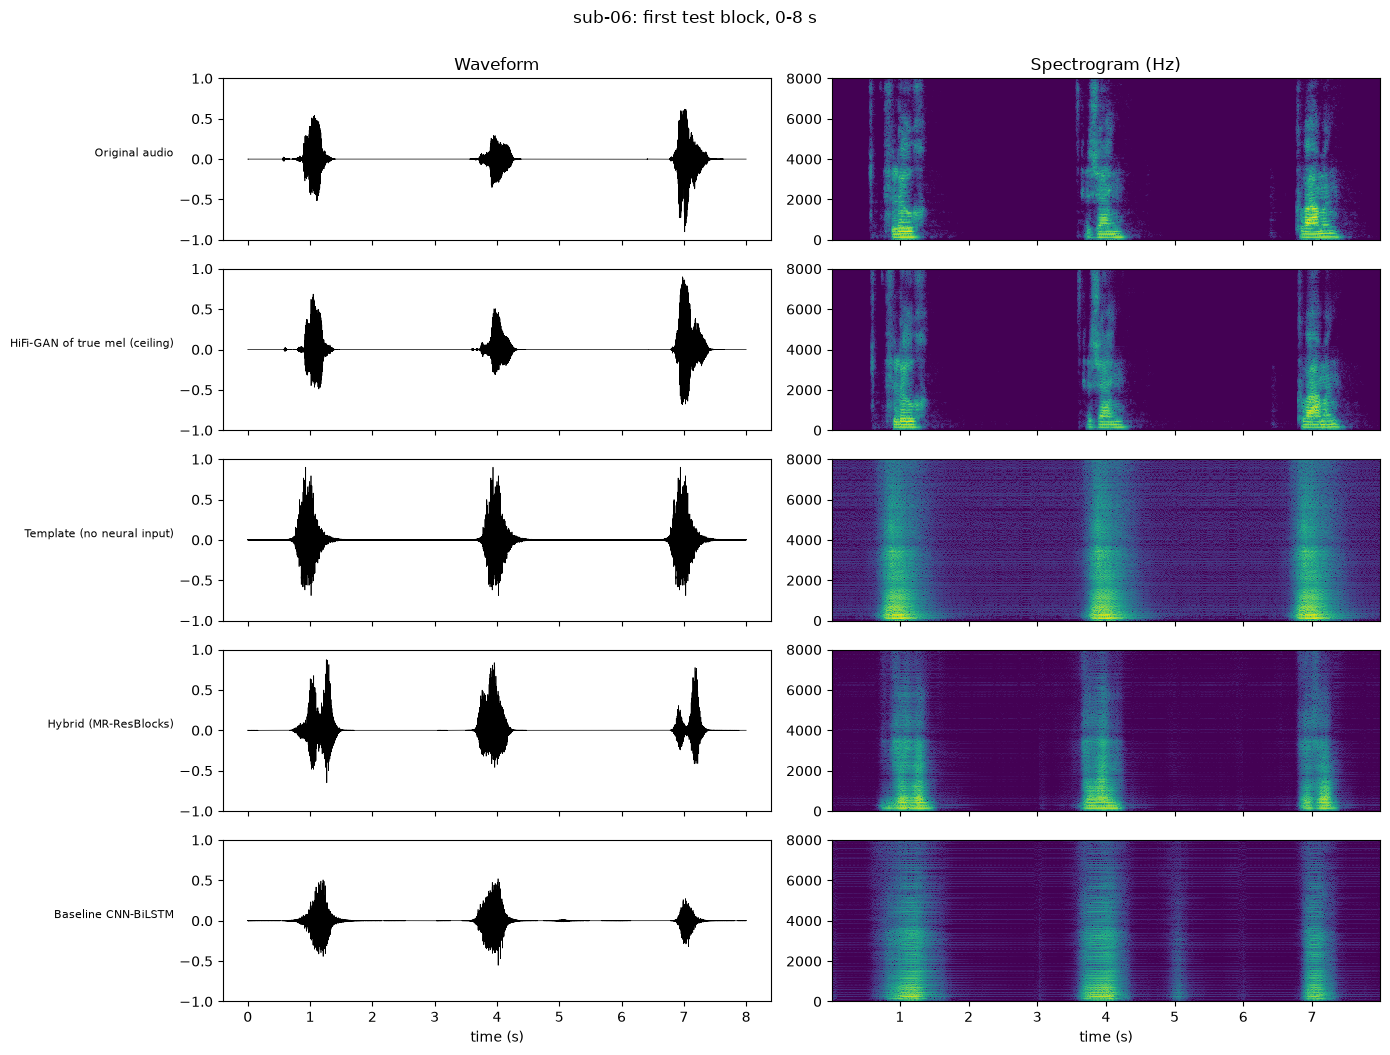

In [26]:
import os, numpy as np, matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import spectrogram

d = r"C:\seeg_v2\features_hifigan\stageA_audio"
sub, t0, dur = "sub-06", 0.0, 8.0            # غيّري t0 لاختيار مقطع آخر (ثوانٍ)
names = ["original", "truth", "template", "hybrid", "baseline"]
titles = {"original": "Original audio", "truth": "HiFi-GAN of true mel (ceiling)", "template": "Template (no neural input)",
          "hybrid": "Hybrid (MR-ResBlocks)", "baseline": "Baseline CNN-BiLSTM"}

fig, ax = plt.subplots(len(names), 2, figsize=(14, 2.1 * len(names)), sharex="col")
for i, n in enumerate(names):
    sr, x = wavfile.read(os.path.join(d, f"{sub}_{n}.wav")); x = x.astype(float) / 32768
    seg = x[int(t0 * sr): int((t0 + dur) * sr)]; t = np.arange(len(seg)) / sr + t0
    ax[i, 0].plot(t, seg, lw=0.5, color="k"); ax[i, 0].set_ylim(-1, 1); ax[i, 0].set_ylabel(titles[n], rotation=0, ha="right", fontsize=8)
    f, tt, S = spectrogram(seg, sr, nperseg=512, noverlap=384)
    ax[i, 1].pcolormesh(tt + t0, f, 10 * np.log10(S + 1e-12), shading="auto", vmin=-110, vmax=-30); ax[i, 1].set_ylim(0, 8000)
ax[-1, 0].set_xlabel("time (s)"); ax[-1, 1].set_xlabel("time (s)")
ax[0, 0].set_title("Waveform"); ax[0, 1].set_title("Spectrogram (Hz)")
plt.suptitle(f"{sub}: first test block, {t0:.0f}-{t0 + dur:.0f} s", y=1.0); plt.tight_layout(); plt.show()

In [23]:
import os, numpy as np
from scipy.io import wavfile
from scipy.signal import butter, sosfiltfilt
from scipy.ndimage import uniform_filter1d
d = r"C:\seeg_v2\features_hifigan\stageA_audio"; sub = "sub-06"

def clean(x, sr):                                   # نفس المعاملات الثابتة لكل الأنظمة
    y = sosfiltfilt(butter(4, [80, 7500], btype="band", fs=sr, output="sos"), x)
    env = uniform_filter1d(np.abs(y), int(0.02 * sr)); thr = 0.05 * env.max()
    gain = uniform_filter1d(np.clip(env / thr, 0, 1), int(0.03 * sr))
    return y * gain

for n in ["truth", "template", "hybrid", "baseline"]:
    sr, x = wavfile.read(os.path.join(d, f"{sub}_{n}.wav")); x = x.astype(float) / 32768
    y = clean(x, sr); y = y / (np.abs(y).max() + 1e-9) * 0.9
    wavfile.write(os.path.join(d, f"{sub}_{n}_clean.wav"), sr, (y * 32767).astype(np.int16))
print("saved *_clean.wav")

saved *_clean.wav


In [32]:
import os
for d in (r"C:\seeg_v2", os.environ["SEEG_OUT_DIR"]):
    p = os.path.join(d, "stageA_run2.log")
    if os.path.exists(p):
        print("found:", p); print(open(p, errors="replace").read()[-1500:]); break
else:
    print("not found in either folder")

found: C:\seeg_v2\stageA_run2.log
52s
  convedsr_null: lr 0.001 -> best validation MSE 1.0290
  convedsr_null: chosen lr = 0.001
  convedsr_null_lr0.001_seed42: mean test PCC -0.009 | template 0.744 | residual -0.008
model      runs                  pcc         template_pcc         residual_pcc        pcc_in_speech   template_in_speech
baseline      3       0.705 +- 0.004       0.744 +- 0.000       0.371 +- 0.001       0.219 +- 0.010       0.236 +- 0.000
baseline_null    1       0.044 +- 0.000       0.744 +- 0.000      -0.007 +- 0.000       0.005 +- 0.000       0.236 +- 0.000
convedsr      3       0.590 +- 0.003       0.744 +- 0.000       0.240 +- 0.019       0.167 +- 0.005       0.236 +- 0.000
convedsr_null    1      -0.009 +- 0.000       0.744 +- 0.000      -0.008 +- 0.000      -0.017 +- 0.000       0.236 +- 0.000
hybrid        3       0.696 +- 0.004       0.744 +- 0.000       0.369 +- 0.006       0.232 +- 0.006       0.236 +- 0.000
hybrid_null    1       0.170 +- 0.000       0.744 +

In [33]:
import os, importlib, stageA_report as R
R.res_dir = lambda out=None, smoke=False: os.path.join(os.environ["SEEG_OUT_DIR"], "stageA_supp")
d = R.load_runs()
print(d.groupby(["model", "seed"]).size())
print(d.groupby("seed")[["pcc", "pcc_in_speech", "residual_pcc"]].mean().round(3))
importlib.reload(R)           # يعيد الدفتر إلى المجلد الأصلي

model        seed
neuroincept  42      10
             123     10
             456     10
dtype: int64
        pcc  pcc_in_speech  residual_pcc
seed                                    
42    0.617          0.208         0.286
123   0.604          0.178         0.275
456   0.612          0.189         0.271


<module 'stageA_report' from 'C:\\seeg_v2\\stageA_report.py'>

In [34]:
import subprocess, sys
r = subprocess.run([sys.executable, "-m", "pip", "install", "pyworld", "pysptk", "setuptools<81"], capture_output=True, text=True)
print(r.stdout[-600:]); print(r.stderr[-600:])

12-win_amd64.whl size=313021 sha256=a3637ba59e7884c10845acc960389d5e78232e6eea91eda7e29c4916bdc25001
  Stored in directory: c:\users\pc\appdata\local\pip\cache\wheels\68\af\c5\666141dca96457488604a3d6e338e19b29f927088b00717d1f
Successfully built pysptk
  Attempting uninstall: setuptools
    Found existing installation: setuptools 84.0.0
    Uninstalling setuptools-84.0.0:
      Successfully uninstalled setuptools-84.0.0


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



In [35]:
r = subprocess.run([sys.executable, "-c", "import pyworld, pysptk; print('WORLD OK')"], capture_output=True, text=True)
print(r.stdout, r.stderr[-500:])

WORLD OK
 C:\seeg_v2\.venv\Lib\site-packages\pysptk\util.py:32: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources



In [36]:
import os, glob, numpy as np, pandas as pd, pyworld as pw, pysptk
from scipy.io import wavfile
AUD = os.path.join(os.environ["SEEG_OUT_DIR"], "stageB_audio")
SR, ORDER, HOPMS = 22050, 24, 5.0

def load(p):
    sr, x = wavfile.read(p); assert sr == SR
    return x.astype(np.float64) / 32768

def mcep(x):
    f0, t = pw.dio(x, SR, frame_period=HOPMS); f0 = pw.stonemask(x, f0, t, SR)
    sp = pw.cheaptrick(x, f0, t, SR)
    return pysptk.sp2mc(sp, order=ORDER, alpha=pysptk.util.mcepalpha(SR))[:, 1:]        # c1..c24 (c0 dropped)

def active_frames(x, n):                       # إطارات الكلام: طاقة الأصل > 5% من أقصاها
    hop, w = int(HOPMS * SR / 1000), int(0.0125 * SR)
    r = np.array([np.sqrt(np.mean(x[max(0, i * hop - w): i * hop + w] ** 2) + 1e-12) for i in range(n)])
    return r > 0.05 * r.max()

rows = []
subs = sorted({os.path.basename(p)[:6] for p in glob.glob(os.path.join(AUD, "sub-*_fold0_original.wav"))})
for sub in subs:
    ref = load(os.path.join(AUD, f"{sub}_fold0_original.wav")); a = mcep(ref); act = active_frames(ref, len(a))
    for p in sorted(glob.glob(os.path.join(AUD, f"{sub}_fold0_*.wav"))):
        s = os.path.basename(p)[len(sub) + 7:-4]
        if s == "original": continue
        y = load(p); n = min(len(ref), len(y)); b = mcep(y[:n]); m = min(len(a), len(b))
        f = (10 / np.log(10)) * np.sqrt(2 * ((a[:m] - b[:m]) ** 2).sum(1))
        rows.append(dict(subject=sub, system=s, mcd_all=f.mean(), mcd_active=f[act[:m]].mean()))
    print(sub, "done", flush=True)
res = pd.DataFrame(rows)
order = ["truth", "template", "linear", "baseline", "hybrid", "neuroincept", "convedsr"]
for col in ("mcd_all", "mcd_active"):
    t = res.pivot(index="subject", columns="system", values=col)[[o for o in order if o in set(res.system)]]
    t.loc["mean"] = t.mean(); print(f"\nMCD (WORLD+SPTK, c1-c24, dB; lower = better) | {col}"); print(t.round(2).to_string())

C:\seeg_v2\.venv\Lib\site-packages\pysptk\util.py:32: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


sub-01 done
sub-02 done
sub-03 done
sub-04 done
sub-05 done
sub-06 done
sub-07 done
sub-08 done
sub-09 done
sub-10 done

MCD (WORLD+SPTK, c1-c24, dB; lower = better) | mcd_all
system   truth  template  linear  baseline  hybrid  neuroincept  convedsr
subject                                                                  
sub-01    5.60      7.32    8.25      7.45    7.61         8.45      8.35
sub-02    5.69      7.63    7.98      6.98    7.11         7.77      7.82
sub-03    6.43      9.54    8.24      7.73    7.79        10.52      8.19
sub-04    5.84      7.49    7.66      7.01    6.95         7.34      7.83
sub-05    6.11      8.24    8.46      7.90    7.75         8.34      8.50
sub-06    5.70      7.08    6.97      6.45    6.40         6.78      7.00
sub-07    5.65      7.80    6.94      6.37    6.62         6.84      6.88
sub-08    5.72      7.01    7.53      7.19    7.19         7.40      7.26
sub-09    5.42      6.84    7.20      6.61    6.48         7.06      7.01
sub-10    

In [ ]:
# ===== constant-output control for STOI/eSTOI (self-contained) =====
import os, sys, glob, json, numpy as np

OUT = r"C:\seeg_v2\out"        # <-- EDIT: the folder that contains sub-01_spec.npy, stageB\, quality\, hifigan_ckpt\

# --- check the folder first ---
need = ["sub-01_spec.npy", "stageB", "quality", "hifigan_ckpt"]
for n in need:
    p = os.path.join(OUT, n)
    print(("OK      " if os.path.exists(p) else "MISSING ") + p)
assert os.path.exists(os.path.join(OUT, "sub-01_spec.npy")), "OUT is wrong: change the first line of this cell"

from pystoi import stoi
sys.path.insert(0, r"C:\seeg_v2")
os.environ["SEEG_OUT_DIR"] = OUT
import stageA_stoi as S

def get_decoder_local(OUT):
    import torch
    from speechbrain.inference.vocoders import HIFIGAN
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    ck = os.path.join(OUT, "hifigan_ckpt"); kw = {}
    try:
        from speechbrain.utils.fetching import LocalStrategy
        kw["local_strategy"] = LocalStrategy.COPY
    except Exception:
        pass
    hifi = HIFIGAN.from_hparams(source=ck, savedir=ck, run_opts={"device": dev}, **kw)
    def decode(mel_t80):
        with torch.no_grad():
            m = torch.tensor(mel_t80.T, dtype=torch.float32)[None].to(dev)
            return hifi.decode_batch(m).squeeze().cpu().numpy()
    return decode

decode = get_decoder_local(OUT)

def score_mel(mel, idx, x):
    v, e = [], []
    for a, b in S.runs_of(idx):
        fr0, fr1 = int(idx[a]), int(idx[b - 1]) + 1
        y = decode(mel[a:b]); ref = x[fr0 * S.HOP: fr1 * S.HOP]; n = min(len(ref), len(y))
        v.append(stoi(ref[:n], y[:n], S.SR, extended=False)); e.append(stoi(ref[:n], y[:n], S.SR, extended=True))
    return float(np.mean(v)), float(np.mean(e))

S_B = json.load(open(os.path.join(OUT, "quality", "stoiB_results.json")))
res = {}
print(f"\n{'sub':7s}{'CONSTANT':>10s}{'':8s}{'Hybrid':>10s}{'':8s}{'NeuroIncept':>12s}")
print(f"{'':7s}{'STOI':>10s}{'eSTOI':>8s}{'STOI':>10s}{'eSTOI':>8s}{'STOI':>12s}{'eSTOI':>8s}")
for sub in [f"sub-{i:02d}" for i in range(1, 11)]:
    spec = np.load(os.path.join(OUT, f"{sub}_spec.npy"))
    sr, x = S.read_wav(glob.glob(os.path.join(OUT, f"{sub}_audio_*.wav"))[0])
    z = np.load(os.path.join(OUT, "stageB", f"hybrid_{sub}_fold0_preds.npz"), allow_pickle=True)
    idx = z[sub + "_idx"]
    mask = np.ones(len(spec), bool); mask[idx] = False
    const = np.tile(spec[mask].mean(0), (len(idx), 1))          # mean log-mel of all NON-test frames
    s, e = score_mel(const, idx, x)
    res[sub] = dict(subject=sub, system="constant", fold=0, stoi=s, estoi=e)
    h = S_B[f"B|hybrid|{sub}|0"]; n = S_B[f"B|neuroincept|{sub}|0"]
    print(f"{sub:7s}{s:10.3f}{e:8.3f}{h['stoi']:10.3f}{h['estoi']:8.3f}{n['stoi']:12.3f}{n['estoi']:8.3f}")

print("\nMEAN over 10 participants: constant STOI %.3f | eSTOI %.3f" % (
    np.mean([r['stoi'] for r in res.values()]), np.mean([r['estoi'] for r in res.values()])))
outf = os.path.join(OUT, "quality", "stoiB_constant_control.json")
json.dump(res, open(outf, "w"), indent=1)
print("saved:", outf)

In [3]:
# ===== ضابط الثابت لـ Stage A (STOI / eSTOI) — مستقلة وتكمل من آخر مشارك إذا توقفت =====
import os, sys, glob, json, time
import numpy as np
OUT = r"C:/seeg_v2/features_hifigan"
os.environ["SEEG_OUT_DIR"] = OUT
if r"C:\seeg_v2" not in sys.path: sys.path.insert(0, r"C:\seeg_v2")
import stageA_stoi as S
from pystoi import stoi

def get_decoder_local(OUT):
    import torch
    from speechbrain.inference.vocoders import HIFIGAN
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    ck = os.path.join(OUT, "hifigan_ckpt"); kw = {}
    try:
        from speechbrain.utils.fetching import LocalStrategy
        kw["local_strategy"] = LocalStrategy.COPY
    except Exception:
        pass
    hifi = HIFIGAN.from_hparams(source=ck, savedir=ck, run_opts={"device": dev}, **kw)
    def decode(mel_t80):
        with torch.no_grad():
            m = torch.tensor(mel_t80.T, dtype=torch.float32)[None].to(dev)
            return hifi.decode_batch(m).squeeze().cpu().numpy()
    return decode

decode = get_decoder_local(OUT)
QD = os.path.join(OUT, "quality"); os.makedirs(QD, exist_ok=True)
JS = os.path.join(QD, "stageA_constant_control.json")
res = json.load(open(JS)) if os.path.exists(JS) else {}
f_any = S.any_pred_file(); z = np.load(f_any)          # نفس فريمات الاختبار (seed 42) المستخدمة في STOI للورقة
print("test frames taken from:", os.path.basename(f_any))

for sub in S.ALL_SUBS:
    key = f"A|constant|{sub}|-"
    if key in res: continue
    t0 = time.time()
    spec = np.load(os.path.join(OUT, f"{sub}_spec.npy"))
    sr, x = S.read_wav(glob.glob(os.path.join(OUT, f"{sub}_audio_*.wav"))[0]); assert sr == S.SR
    idx = z[sub + "_idx"]
    test = np.zeros(len(spec), bool); test[idx] = True
    const = spec[~test].mean(0)                          # متوسط log-mel لكل الفريمات غير الاختبارية (كما في Stage B)
    v, e = [], []
    for a, b in S.runs_of(idx):                          # كل run = كتلة اختبار (مطابق لـ stageA_stoi.py)
        fr0, fr1 = int(idx[a]), int(idx[b - 1]) + 1
        y = decode(np.tile(const, (b - a, 1)).astype(np.float32))
        ref = x[fr0 * S.HOP: fr1 * S.HOP]; n = min(len(ref), len(y))
        v.append(stoi(ref[:n], y[:n], S.SR, extended=False)); e.append(stoi(ref[:n], y[:n], S.SR, extended=True))
    res[key] = dict(stage="A", system="constant", subject=sub, stoi=float(np.mean(v)), estoi=float(np.mean(e)), blocks=len(v))
    json.dump(res, open(JS, "w"), indent=1)
    print(f"{sub}: constant STOI {np.mean(v):.3f} | eSTOI {np.mean(e):.3f} | {len(v)} blocks | {time.time()-t0:.0f}s", flush=True)

# ---- مقارنة مع الأنظمة الموجودة في الورقة (Stage A, seed 42)
import pandas as pd
pd.set_option("display.width", 200)
old = pd.DataFrame(json.load(open(os.path.join(OUT, "stageA_stoi", "stoi_results.json"))).values())
new = pd.DataFrame(list(res.values()))
allr = pd.concat([old[["subject", "system", "stoi", "estoi"]], new[["subject", "system", "stoi", "estoi"]]])
print("\nSTOI per participant:"); print(allr.pivot(index="subject", columns="system", values="stoi").round(3).to_string())
m = allr.groupby("system")[["stoi", "estoi"]].mean().round(3)
print("\nmean over participants:"); print(m.to_string())
c = m.loc["constant", "stoi"]
print(f"\nconstant STOI = {c:.3f};  systems with mean STOI ABOVE it:",
      [s for s in m.index if s not in ('constant', 'truth') and m.loc[s, 'stoi'] > c])
print("saved ->", JS)

C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\nn\utils\weight_norm.py:28: UserWarning: torch.nn.utils.weight_norm is deprecated in favor of torch.nn.utils.parametrizations.weight_norm.
  warnings.warn("torch.nn.utils.weight_norm is deprecated in favor of torch.nn.utils.parametrizations.weight_norm.")


test frames taken from: hybrid_lr0.0001_seed42_preds.npz
sub-01: constant STOI 0.422 | eSTOI -0.007 | 2 blocks | 35s
sub-02: constant STOI 0.506 | eSTOI -0.005 | 2 blocks | 30s
sub-03: constant STOI 0.534 | eSTOI 0.010 | 2 blocks | 32s
sub-04: constant STOI 0.510 | eSTOI -0.005 | 2 blocks | 29s
sub-05: constant STOI 0.494 | eSTOI 0.004 | 2 blocks | 31s
sub-06: constant STOI 0.524 | eSTOI -0.019 | 2 blocks | 29s
sub-07: constant STOI 0.544 | eSTOI 0.013 | 2 blocks | 32s
sub-08: constant STOI 0.521 | eSTOI -0.006 | 2 blocks | 33s
sub-09: constant STOI 0.539 | eSTOI 0.005 | 2 blocks | 31s
sub-10: constant STOI 0.529 | eSTOI -0.018 | 2 blocks | 31s

STOI per participant:
system   baseline  constant  convedsr  hybrid  linear  neuroincept  template  truth
subject                                                                            
sub-01      0.286     0.422     0.201   0.291   0.194        0.178     0.291  0.676
sub-02      0.330     0.506     0.307   0.296   0.339        0.213     0